# Getaround - quel délai minimal imposer entre deux locations ?

*Certification RNCP35288 (Concepteur Développeur en Science des Données), bloc 5 -
industrialisation d'un algorithme et automatisation des décisions. Partie « analyse des
données » du projet Getaround (le modèle de prix, l'API et le tableau de bord sont dans les
dossiers `train/`, `api/` et `dashboard/` du dépôt).*

**Contexte (énoncé)** : quand un conducteur rend la voiture en retard, le conducteur suivant
attend, et annule parfois. Getaround envisage d'imposer un **délai minimal entre deux
locations** : une voiture ne serait plus proposée si le créneau demandé est trop proche d'une
location déjà réservée. Cela évite des conflits mais **fait perdre des locations**. Le chef de
produit doit choisir le **seuil** (durée du délai) et le **périmètre** (toutes les voitures, ou
seulement les voitures « Connect », ouvertes par smartphone sans rencontre avec le
propriétaire).

**Questions de l'énoncé** : (1) quelle part du revenu des propriétaires serait touchée ?
(2) combien de locations seraient touchées selon le seuil et le périmètre ? (3) à quelle
fréquence les conducteurs sont-ils en retard, et quel impact sur le conducteur suivant ?
(4) combien de cas problématiques seraient résolus selon le seuil et le périmètre ?

**Plan** : section 1, données et qualité ; section 2, fréquence des retards (Q3) ; section 3,
impact sur le conducteur suivant (Q3) ; section 4, arbitrage seuil × périmètre (Q2 et Q4) ;
section 5, part des locations bloquées, indicateur de substitution du revenu (Q1) ;
section 6, recommandation ; section 7, exploration des données de prix. Les définitions (cas
problématique, location bloquée, cas résolu) sont dans le module `retards.py`, partagé avec
le tableau de bord.

### CHOIX

- **Retenu** : un notebook qui raisonne et affiche ; les calculs réutilisables sont dans
  `retards.py` (indicateurs partagés avec le tableau de bord).
- **Retenu** : un indicateur de substitution du revenu (part des locations terminées
  bloquées), parce que le classeur n'a aucun prix par location. **Écarté** : estimer un revenu
  avec le fichier de prix, qui décrit d'autres voitures sans lien avec ces locations.
- **Retenu** : une recommandation présentée comme un arbitrage assumé (60 minutes, toutes les
  voitures). **Écarté** : la présenter comme un optimum, alors que la courbe n'a pas de coude.
- **Écarté** : conclure à une cause. L'écart d'annulation est une association.
- **Écarté** : retirer les retards extrêmes. Ils sont gardés ; médiane et tranches y résistent.

### OÙ

- Racine du dépôt.
- Il appelle `retards.py`, lit `data/get_around_delay_analysis.xlsx` et
  `data/get_around_pricing_project.csv`, et s'appuie sur pandas et matplotlib.
- Le tableau de bord `dashboard/app.py` rejoue l'arbitrage avec les mêmes fonctions de
  `retards.py`.

### COMMENT

- Sections 1 et 2 : qualité des données, puis fréquence des retards par tranche
  (`retards.tranche_de_retard`). Section 3 : cas problématiques (`retards.preparer`), tableau
  croisé des annulations.
- Section 4 : arbitrage seuil × périmètre (`retards.tableau_seuils`). Section 5 : indicateur de
  substitution du revenu. Sections 6 et 7 : recommandation, exploration des données de prix.

### POURQUOI

- Les quatre questions (revenu touché, locations touchées, fréquence des retards, cas
  résolus) viennent de l'énoncé du projet.
- Les définitions (cas problématique, location bloquée, cas résolu) sont celles du
  module `retards.py`.
- Les chiffres de ce notebook sont ceux de son exécution complète.

### JOURNALISATION

- Aucune journalisation applicative : les sorties des cellules (impressions, tableaux, figures)
  sont la trace de l'analyse. Rien n'est tiré au hasard, deux exécutions donnent les mêmes
  sorties. Les métadonnées de chaque cellule gardent l'heure de son exécution.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import retards

DONNEES = Path("data")
classeur = pd.ExcelFile(DONNEES / "get_around_delay_analysis.xlsx")
print("Feuilles :", classeur.sheet_names)
documentation = classeur.parse("Documentation")
pd.set_option("display.max_colwidth", 140)
display(documentation)

Feuilles : ['rentals_data', 'Documentation']


,field name,Comment
0,rental_id,Unique identifier of the rental
1,car_id,Unique identifier of the car
2,checkin_type,Flow used for both checkin and checkout. (ie. access and return the car)\nmobile = rental agreement signed on the owner's smartphone\nco...
3,state,canceled means that the rental did not happen (was canceled by the driver or the owner).
4,delay_at_checkout_in_minutes,Difference in minutes between the rental end time requested by the driver when booking the car and the actual time the driver completed ...
5,previous_ended_rental_id,id of the previous ended rental of the car (NULL when no previous rental or delay with previous rental higher than 12 hours)
6,time_delta_with_previous_rental_in_minutes,"Difference in minutes between this rental planned start time and the previous rental planned end time (when lower than 12 hours, NULL if..."


## 1. Données et contrôles de qualité

In [2]:
locations = classeur.parse("rentals_data")
print(f"{len(locations)} locations, {locations['car_id'].nunique()} voitures")
print(locations.dtypes.to_string())
print("\nValeurs manquantes :")
print(locations.isna().sum().to_string())
print("\nÉtat des locations :", locations["state"].value_counts().to_dict())
print("Type de check-in :", locations["checkin_type"].value_counts().to_dict())

21310 locations, 8143 voitures
rental_id                                       int64
car_id                                          int64
checkin_type                                      str
state                                             str
delay_at_checkout_in_minutes                  float64
previous_ended_rental_id                      float64
time_delta_with_previous_rental_in_minutes    float64

Valeurs manquantes :
rental_id                                         0
car_id                                            0
checkin_type                                      0
state                                             0
delay_at_checkout_in_minutes                   4964
previous_ended_rental_id                      19469
time_delta_with_previous_rental_in_minutes    19469

État des locations : {'ended': 18045, 'canceled': 3265}
Type de check-in : {'mobile': 17003, 'connect': 4307}


In [3]:
# Cohérence : un identifiant de location précédente va toujours avec un écart prévu.
precedente_connue = locations["previous_ended_rental_id"].notna()
ecart_connu = locations["time_delta_with_previous_rental_in_minutes"].notna()
print(
    "Identifiant précédent sans écart prévu (ou l'inverse) :",
    int((precedente_connue != ecart_connu).sum()),
)
# Les retards manquants correspondent-ils aux locations annulées (jamais rendues) ?
print(
    "Retard manquant selon l'état :",
    locations.groupby("state")["delay_at_checkout_in_minutes"]
    .apply(lambda s: int(s.isna().sum()))
    .to_dict(),
)
# Valeurs extrêmes : un retard (ou une avance) de plus d'un jour.
retard = locations["delay_at_checkout_in_minutes"]
print(
    f"Retards de plus d'un jour : {int((retard > 1440).sum())} ; avances de plus d'un jour : "
    f"{int((retard < -1440).sum())} ; extrêmes : {retard.min():.0f} et {retard.max():.0f} min"
)
# Écarts prévus : de 0 à 12 h, par pas de 30 minutes (entiers, pour une lecture plus claire).
print(
    "Écarts prévus possibles (min) :",
    sorted(
        int(v) for v in locations["time_delta_with_previous_rental_in_minutes"].dropna().unique()
    ),
)

Identifiant précédent sans écart prévu (ou l'inverse) : 0
Retard manquant selon l'état : {'canceled': 3264, 'ended': 1700}
Retards de plus d'un jour : 188 ; avances de plus d'un jour : 41 ; extrêmes : -22433 et 71084 min
Écarts prévus possibles (min) : [0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360, 390, 420, 450, 480, 510, 540, 570, 600, 630, 660, 690, 720]


**Décisions de qualité** :

- presque toutes les **locations annulées** n'ont pas de retard (3 264 sur 3 265 : la voiture
  n'a pas été rendue ; une seule en a un) : elles restent dans le total des locations, mais
  sont exclues des calculs de retard ;
- les **retards extrêmes** (plus d'un jour, jusqu'à près de 50 jours) sont probablement des
  erreurs de saisie ou des litiges : ils sont gardés pour la logique métier (un tel retard
  pénalise bien le conducteur suivant) mais les calculs de retard utilisent la
  **médiane** et des **tranches**, insensibles à ces valeurs ;
- 1 700 locations **terminées** n'ont pas de retard enregistré (donnée manquante à la
  source) : elles sont exclues des calculs de retard, sans imputation ;
- aucune ligne n'est supprimée : le total de 21 310 locations sert de base aux parts.

In [4]:
df = retards.preparer(locations)
avec_precedente = df[df["previous_ended_rental_id"].notna()]
print(
    f"Locations précédées d'une autre à moins de 12 h : {len(avec_precedente)} "
    f"({len(avec_precedente) / len(df):.1%})"
)
print(
    f"... dont le retard de la précédente est connu : "
    f"{int(avec_precedente['retard_precedent'].notna().sum())}"
)

Locations précédées d'une autre à moins de 12 h : 1841 (8.6%)
... dont le retard de la précédente est connu : 1729


## 2. À quelle fréquence les conducteurs sont-ils en retard ? (Q3)

In [5]:
rendues = df[df["state"] == "ended"].dropna(subset=["delay_at_checkout_in_minutes"])
tranches = retards.tranche_de_retard(rendues["delay_at_checkout_in_minutes"])
repartition = pd.crosstab(tranches, rendues["checkin_type"], normalize="columns").mul(100).round(1)
repartition["ensemble"] = tranches.value_counts(normalize=True).mul(100).round(1)
print(f"Locations rendues avec un retard connu : {len(rendues)}")
en_retard = rendues["delay_at_checkout_in_minutes"] > 0
retard_median = rendues.loc[en_retard, "delay_at_checkout_in_minutes"].median()
print(
    f"Part en retard : {en_retard.mean():.1%} ; "
    f"retard médian des retardataires : {retard_median:.0f} min"
)
print(
    rendues.groupby("checkin_type")["delay_at_checkout_in_minutes"]
    .agg(part_en_retard=lambda s: round((s > 0).mean() * 100, 1), retard_median_min="median")
    .to_string()
)
display(repartition)

Locations rendues avec un retard connu : 16345
Part en retard : 57.5% ; retard médian des retardataires : 53 min
              part_en_retard  retard_median_min
checkin_type                                   
connect                 42.9               -9.0
mobile                  61.4               14.0


checkin_type,connect,mobile,ensemble
delay_at_checkout_in_minutes,,,
à l'heure ou en avance,57.1,38.6,42.5
0-15 min,10.3,12.7,12.2
15-60 min,16.4,19.1,18.5
1-2 h,8.6,11.9,11.2
2-24 h,7.6,16.3,14.5
plus de 24 h,0.1,1.4,1.2


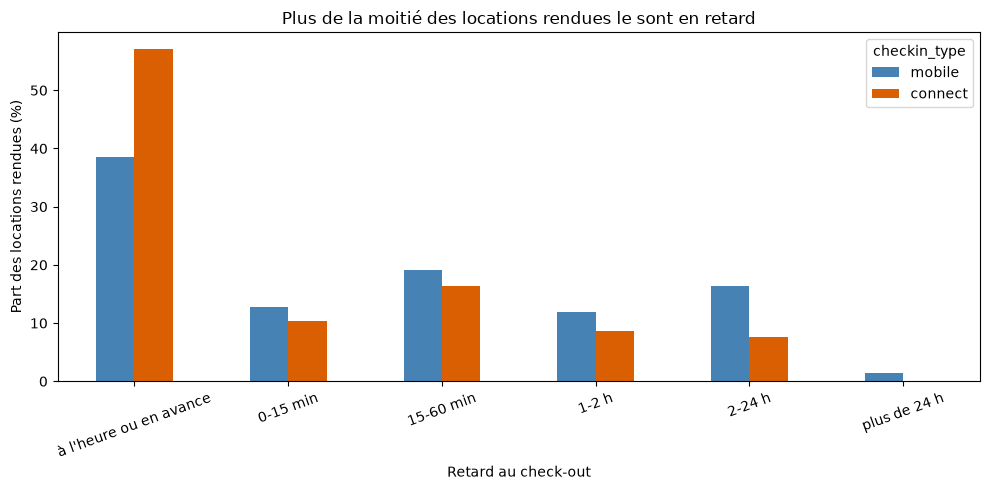

In [6]:
ax = repartition[["mobile", "connect"]].plot.bar(figsize=(10, 5), color=["steelblue", "#d95f02"])
ax.set_title("Plus de la moitié des locations rendues le sont en retard")
ax.set_xlabel("Retard au check-out")
ax.set_ylabel("Part des locations rendues (%)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

> **Interprétation** : parmi les 16 345 locations rendues dont le retard est connu,
> **57,5 % sont rendues en retard**, avec un retard médian de 53 minutes chez les
> retardataires ; 14,5 % ont entre 2 et 24 heures de retard. Les conducteurs **Connect** sont
> nettement plus ponctuels : 42,9 % de retards et un retour médian 9 minutes en avance, contre
> 61,4 % de retards et 14 minutes de retard médian pour les check-in sur mobile.
>
> **Hypothèse, non testée ici** : en check-in mobile, conducteur et propriétaire se
> rencontrent et pourraient convenir à l'oral d'un retour plus tardif, ce qui n'existe pas en
> Connect. Les données n'enregistrent aucun accord de ce genre, et d'autres explications sont
> possibles (profils de conducteurs ou de voitures différents selon le mode de check-in).

## 3. Quel impact sur le conducteur suivant ? (Q3)

Locations dont la précédente (moins de 12 h avant) a un retard connu : 1729
Cas problématiques (le conducteur suivant attend) : 218 (12.6% de ces locations)
Attente du conducteur suivant : médiane 26.5 min ; plus d'une heure dans 30% des cas
Taux d'annulation (%) - sans attente : 11.2 ; avec attente : 17.0
Cas problématiques par type de check-in : {'mobile': 149, 'connect': 69}


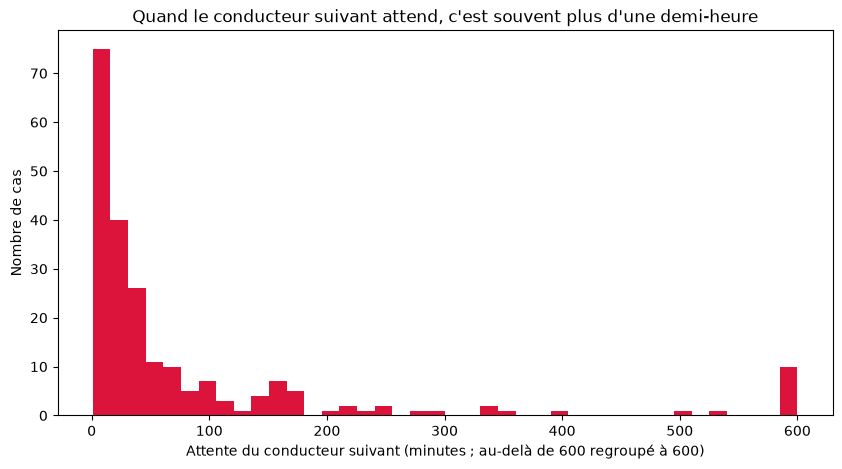

In [7]:
connus = avec_precedente.dropna(subset=["retard_precedent"])
problemes = connus[connus["cas_problematique"]]
print(f"Locations dont la précédente (moins de 12 h avant) a un retard connu : {len(connus)}")
print(
    f"Cas problématiques (le conducteur suivant attend) : {len(problemes)} "
    f"({len(problemes) / len(connus):.1%} de ces locations)"
)
print(
    f"Attente du conducteur suivant : médiane {problemes['retard_residuel'].median():.1f} min ; "
    f"plus d'une heure dans {(problemes['retard_residuel'] > 60).mean():.0%} des cas"
)
annulation = connus.groupby("cas_problematique")["state"].apply(
    lambda s: round((s == "canceled").mean() * 100, 1)
)
print(
    "Taux d'annulation (%) - sans attente :",
    annulation.get(False),
    "; avec attente :",
    annulation.get(True),
)
print(
    "Cas problématiques par type de check-in :", problemes["checkin_type"].value_counts().to_dict()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(problemes["retard_residuel"].clip(upper=600), bins=40, color="crimson")
ax.set_title("Quand le conducteur suivant attend, c'est souvent plus d'une demi-heure")
ax.set_xlabel("Attente du conducteur suivant (minutes ; au-delà de 600 regroupé à 600)")
ax.set_ylabel("Nombre de cas")
plt.show()

**Les annulations quand le conducteur suivant attend.** Je croise l'attente (oui ou non) avec
l'annulation de la location (oui ou non), puis je compare les deux taux d'annulation.

In [8]:
# Tableau 2 × 2 sur les locations dont le retard de la précédente est connu, puis les deux taux
# d'annulation et leur écart.
attente = connus["cas_problematique"]
annulee = connus["state"] == "canceled"
croisement = pd.crosstab(attente, annulee)
croisement.index = pd.Index(["sans attente", "avec attente"])
croisement.columns = pd.Index(["non annulée", "annulée"])
print(croisement.to_string(), "\n")
taux_avec = float(annulee[attente].mean())
taux_sans = float(annulee[~attente].mean())
print(
    f"Taux d'annulation : {taux_avec:.1%} avec attente contre {taux_sans:.1%} sans ; "
    f"écart {(taux_avec - taux_sans) * 100:+.1f} points"
)

# Réserve : une location annulée n'a pas eu lieu, l'attente y est hypothétique.
annulees_en_attente = int((problemes["state"] == "canceled").sum())
print(
    f"Parmi les {len(problemes)} « cas d'attente », {annulees_en_attente} sont des locations "
    f"annulées ({annulees_en_attente / len(problemes):.1%}) : l'attente y est hypothétique."
)

              non annulée  annulée
sans attente         1342      169
avec attente          181       37

 

Taux d'annulation : 17.0% avec attente contre 11.2% sans ; écart +5.8 points
Parmi les 218 « cas d'attente », 37 sont des locations annulées (17.0%) : l'attente y est hypothétique.


> **Interprétation** : seules 1 841 locations (8,6 %) suivent une autre location de la même
> voiture à moins de 12 heures ; c'est uniquement là qu'un retard peut gêner le conducteur
> suivant. Pour les 1 729 dont le retard de la précédente est connu, **218 sont des cas
> problématiques** (12,6 %) : le conducteur suivant attend, 26,5 minutes en médiane et plus d'une
> heure dans 30 % des cas. Les deux tiers des cas problématiques (149 sur 218) concernent des
> voitures en check-in mobile.
>
> **Effet sur les annulations** : 17,0 % des locations avec attente sont annulées, contre
> 11,2 % quand la voiture revient à temps, soit +5,8 points. Cet écart est observé sur 218 cas
> seulement, à lire avec prudence. Deux réserves : (1) c'est une **association**, pas une
> causalité démontrée ;
> (2) **37 des 218 « cas d'attente » sont des locations annulées** : l'attente y est
> hypothétique (la voiture n'a pas été prise, et les données ne disent pas si l'annulation
> a précédé ou suivi le retard de la location précédente).

## 4. L'arbitrage : locations perdues contre cas résolus (Q2 et Q4)

Pour chaque seuil de 0 à 12 heures (par pas de 30 minutes) et chaque périmètre, je compte les
locations qui n'auraient pas pu être réservées et les cas problématiques évités.

In [9]:
seuils = range(0, 721, 30)
arbitrage = retards.tableau_seuils(df, seuils)
total_problemes = int(df["cas_problematique"].sum())
print(f"Total des locations : {len(df)} ; total des cas problématiques : {total_problemes}")
colonnes_arbitrage = [
    "perimetre",
    "seuil_min",
    "locations_bloquees",
    "part_locations_pct",
    "cas_resolus",
    "part_cas_resolus_pct",
]
seuils_affiches = [30, 60, 90, 120, 180, 240, 360, 720]
arbitrage.loc[arbitrage["seuil_min"].isin(seuils_affiches), colonnes_arbitrage]

Total des locations : 21310 ; total des cas problématiques : 218


,perimetre,seuil_min,locations_bloquees,part_locations_pct,cas_resolus,part_cas_resolus_pct
1,toutes,30,279,1.31,116,53.2
2,toutes,60,401,1.88,146,67.0
3,toutes,90,584,2.74,172,78.9
4,toutes,120,666,3.13,180,82.6
6,toutes,180,870,4.08,196,89.9
8,toutes,240,1001,4.70,202,92.7
12,toutes,360,1170,5.49,208,95.4
24,toutes,720,1711,8.03,216,99.1
26,connect,30,131,0.61,40,18.3
27,connect,60,181,0.85,48,22.0


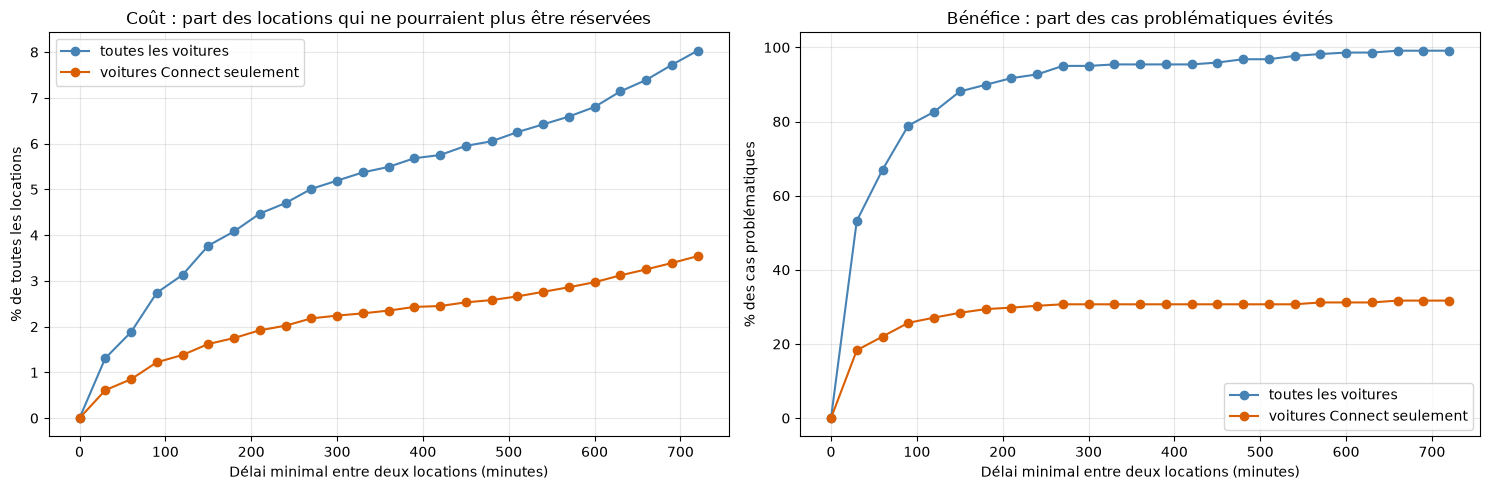

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for perimetre, couleur in [("toutes", "steelblue"), ("connect", "#d95f02")]:
    sous = arbitrage[arbitrage["perimetre"] == perimetre]
    libelle = retards.PERIMETRES[perimetre]
    axes[0].plot(
        sous["seuil_min"], sous["part_locations_pct"], marker="o", color=couleur, label=libelle
    )
    axes[1].plot(
        sous["seuil_min"], sous["part_cas_resolus_pct"], marker="o", color=couleur, label=libelle
    )
axes[0].set_title("Coût : part des locations qui ne pourraient plus être réservées")
axes[0].set_ylabel("% de toutes les locations")
axes[1].set_title("Bénéfice : part des cas problématiques évités")
axes[1].set_ylabel("% des cas problématiques")
for ax in axes:
    ax.set_xlabel("Délai minimal entre deux locations (minutes)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Rendement de chaque demi-heure supplémentaire : combien de cas résolus en plus pour combien de
# locations perdues en plus. Question posée : la courbe présente-t-elle un coude, c'est-à-dire un
# seuil au-delà duquel le rendement chute brutalement ?
rendement = arbitrage.copy()
rendement["cas_resolus_en_plus"] = rendement.groupby("perimetre")["cas_resolus"].diff()
rendement["locations_perdues_en_plus"] = rendement.groupby("perimetre")[
    "locations_bloquees"
].diff()
rendement["cas_resolus_par_location_perdue"] = (
    rendement["cas_resolus_en_plus"] / rendement["locations_perdues_en_plus"]
).round(2)
rendement[rendement["seuil_min"].between(30, 240)][
    [
        "perimetre",
        "seuil_min",
        "cas_resolus_en_plus",
        "locations_perdues_en_plus",
        "cas_resolus_par_location_perdue",
    ]
]

,perimetre,seuil_min,cas_resolus_en_plus,locations_perdues_en_plus,cas_resolus_par_location_perdue
1,toutes,30,116.0,279.0,0.42
2,toutes,60,30.0,122.0,0.25
3,toutes,90,26.0,183.0,0.14
4,toutes,120,8.0,82.0,0.10
5,toutes,150,12.0,137.0,0.09
6,toutes,180,4.0,67.0,0.06
7,toutes,210,4.0,83.0,0.05
8,toutes,240,2.0,48.0,0.04
26,connect,30,40.0,131.0,0.31
27,connect,60,8.0,50.0,0.16


> **Interprétation** : sur **toutes les voitures**, un délai de 30 minutes bloquerait 279
> locations (1,3 % du total) et éviterait 116 cas problématiques (53 %) ; 60 minutes : 401
> locations (1,9 %) pour 146 cas évités (67 %) ; 120 minutes : 666 locations (3,1 %) pour 180
> cas (83 %). Sur les **seules voitures Connect**, le coût est plus de deux fois plus faible
> (0,85 % des locations à 60 minutes) mais le bénéfice plafonne à 69 cas (32 % du total) : la
> majorité des cas problématiques concerne des voitures en check-in mobile.
>
> Le **rendement** de chaque demi-heure supplémentaire décroît de façon continue : 0,42 cas
> évité par location perdue pour les 30 premières minutes, 0,25 de 30 à 60 minutes, 0,14 de 60
> à 90, 0,10 de 90 à 120, puis 0,09 ou moins. **Il n'y a pas de coude net** qui désignerait un
> seuil optimal : le choix du seuil est un arbitrage entre coût et bénéfice, à assumer, et non
> une valeur que la courbe imposerait.

## 5. Quelle part du revenu des propriétaires serait touchée ? (Q1)

Le fichier **ne contient aucun prix par location** : la part du revenu touchée ne peut donc
pas être calculée. Je propose un **indicateur de substitution** : la part des locations
bloquées, calculée sur les seules locations **terminées**, puisqu'une location annulée ne
rapporte rien. Ce n'est ni un majorant ni un minorant du revenu perdu (voir
l'interprétation ci-dessous). Le fichier de prix du projet décrit d'autres voitures, sans lien
avec ces locations : il ne permet pas de les valoriser et n'est pas utilisé ici.

In [12]:
terminees = df["state"] == "ended"
bloquees_60 = retards.bloquees(df, 60, "toutes")
n_terminees_bloquees = int((bloquees_60 & terminees).sum())
print(
    f"Toutes voitures, 60 min : {n_terminees_bloquees} locations terminées bloquées sur "
    f"{int(terminees.sum())} = {n_terminees_bloquees / terminees.sum():.2%}"
)
print(
    f"À titre de comparaison, en gardant les annulées : {int(bloquees_60.sum())} sur {len(df)} "
    f"= {bloquees_60.mean():.2%}"
)
# Les locations bloquées sont-elles des locations « moyennes » ? Part des voitures Connect.
connect = df["checkin_type"] == "connect"
print(
    f"Voitures Connect : {connect.mean():.1%} de toutes les locations, "
    f"{connect[bloquees_60].mean():.1%} des locations bloquées à 60 minutes"
)
indicateur = arbitrage.loc[
    arbitrage["seuil_min"].isin([30, 60, 90, 120, 180]),
    [
        "perimetre",
        "seuil_min",
        "locations_bloquees",
        "locations_terminees_bloquees",
        "part_terminees_pct",
    ],
].rename(columns={"part_terminees_pct": "part_terminees_bloquees_pct"})
display(indicateur)

Toutes voitures, 60 min : 358 locations terminées bloquées sur 18045 = 1.98%
À titre de comparaison, en gardant les annulées : 401 sur 21310 = 1.88%
Voitures Connect : 20.2% de toutes les locations, 45.1% des locations bloquées à 60 minutes


,perimetre,seuil_min,locations_bloquees,locations_terminees_bloquees,part_terminees_bloquees_pct
1,toutes,30,279,244,1.35
2,toutes,60,401,358,1.98
3,toutes,90,584,518,2.87
4,toutes,120,666,592,3.28
6,toutes,180,870,773,4.28
26,connect,30,131,109,0.60
27,connect,60,181,156,0.86
28,connect,90,260,221,1.22
29,connect,120,295,252,1.40
31,connect,180,372,317,1.76


> **Interprétation** : avec un délai de 60 minutes sur toutes les voitures, 358 locations
> terminées sur 18 045 auraient été bloquées, soit **1,98 %** (en comptant aussi les locations
> annulées, qui ne rapportent rien : 401 sur 21 310, soit 1,88 %) ; à 120 minutes, 3,28 %.
> Sur les seules voitures Connect : 0,86 % à 60 minutes. Ce sont des **parts de locations
> bloquées**, pas des parts de revenu :
>
> - les locations bloquées ne sont pas des locations moyennes : ce sont des locations qui
>   s'enchaînent à moins de 12 heures, et les voitures Connect y sont surreprésentées (45,1 %
>   des locations bloquées à 60 minutes, contre 20,2 % de l'ensemble). Rien n'autorise à leur
>   supposer le revenu moyen ;
> - une partie des conducteurs refusés réserverait un autre créneau ou une autre voiture (la
>   perte réelle serait plus faible), mais des locations bloquées peuvent aussi valoir plus
>   que la moyenne (elle serait plus forte) : le sens de l'écart n'est pas connu ;
> - mesurer la perte réelle suppose le prix de chaque location.

## 6. Recommandation au chef de produit

**Recommandation : un délai minimal de 60 minutes, sur toutes les voitures.**

- **Pourquoi toutes les voitures** : les deux tiers des conflits concernent des voitures en
  check-in mobile ; se limiter aux voitures Connect laisserait 68 % des cas problématiques sans
  solution.
- **Pourquoi 60 minutes** : c'est un **arbitrage assumé**, pas un optimum lu sur la courbe (le
  rendement décroît de façon continue, sans coude, voir la section 4). Ce seuil évite 67 % des
  cas problématiques (146 sur 218) pour 1,9 % des locations bloquées (2,0 % des locations
  terminées) ; passer à 90 minutes ne résoudrait que 26 cas de plus pour 183 locations
  bloquées de plus.
- **Variante prudente** : 30 minutes (53 % des cas évités pour 1,3 % des locations) si la
  priorité est le revenu ; 90 à 120 minutes si la priorité est l'expérience client.
- **Suivi** : le tableau de bord permet de rejouer l'arbitrage pour tout seuil.
- **Limites** : les cas problématiques ne sont observables que pour les locations rapprochées
  (moins de 12 h) dont le retard précédent est connu ; l'écart d'annulation est une
  association observée sur 218 cas seulement, pas une causalité démontrée ; le revenu par
  location n'est pas dans les données ; l'effet réel des refus (report de la réservation) ne
  se mesure qu'en production.

## 7. Exploration des données de prix

Le fichier `get_around_pricing_project.csv` est distinct des locations : il décrit des voitures
et leur prix de location par jour, et c'est le jeu d'entraînement du modèle de prix
(`train/train.py`, API, page « Prix conseillé » du tableau de bord). Je le contrôle avant de
s'y fier : distributions, valeurs extrêmes, catégories rares, corrélations.

In [13]:
prix = pd.read_csv(DONNEES / "get_around_pricing_project.csv", index_col=0)
print(
    f"{len(prix)} voitures, {prix['model_key'].nunique()} marques, "
    f"valeurs manquantes : {int(prix.isna().sum().sum())}, "
    f"doublons : {int(prix.duplicated().sum())}"
)
numeriques = ["mileage", "engine_power", "rental_price_per_day"]
prix[numeriques].describe(percentiles=[0.01, 0.5, 0.99]).round(1)

4843 voitures, 28 marques, valeurs manquantes : 0, doublons : 0


,mileage,engine_power,rental_price_per_day
count,4843.0,4843.0,4843.0
mean,140962.8,129.0,121.2
std,60196.7,39.0,33.6
min,-64.0,0.0,10.0
1%,17759.2,85.0,28.0
50%,141080.0,120.0,119.0
99%,320967.0,240.0,216.0
max,1000376.0,423.0,422.0


Kilométrage négatif ou puissance nulle :
     model_key  mileage  engine_power  rental_price_per_day
2938   Renault      -64           230                   274
3765    Nissan    81770             0                   108

Plus grands kilométrages :
     model_key  mileage  engine_power  rental_price_per_day
3732   Citroën  1000376            90                    37
557    Renault   484615           120                    91
2350   Peugeot   477571            85                    35

Plus grandes puissances :
     model_key  mileage  engine_power  rental_price_per_day
4146    Suzuki     2970           423                   287
3601      Mini   150187           412                   204
1      Citroën    13929           317                   264

Prix minimal : 10 €, atteint par 7 voitures ; 1 voiture(s) au-delà de 500 000 km ; 10 voitures au-delà de 300 ch


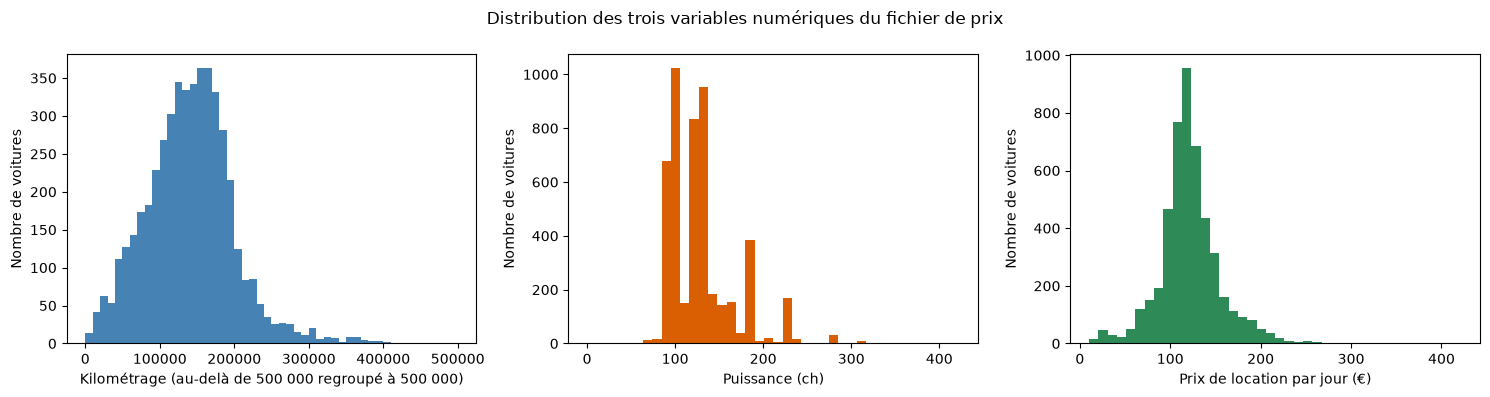

In [14]:
# Valeurs impossibles : un kilométrage négatif, une puissance nulle.
colonnes_voiture = ["model_key", "mileage", "engine_power", "rental_price_per_day"]
print("Kilométrage négatif ou puissance nulle :")
print(prix.loc[(prix["mileage"] < 0) | (prix["engine_power"] == 0), colonnes_voiture].to_string())
# Valeurs extrêmes mais possibles : les plus grands kilométrages et puissances.
print("\nPlus grands kilométrages :")
print(prix.nlargest(3, "mileage")[colonnes_voiture].to_string())
print("\nPlus grandes puissances :")
print(prix.nlargest(3, "engine_power")[colonnes_voiture].to_string())
prix_min = prix["rental_price_per_day"].min()
au_prix_min = int((prix["rental_price_per_day"] == prix_min).sum())
print(
    f"\nPrix minimal : {prix_min} €, atteint par {au_prix_min} voitures ; "
    f"{int((prix['mileage'] > 500_000).sum())} voiture(s) au-delà de 500 000 km ; "
    f"{int((prix['engine_power'] > 300).sum())} voitures au-delà de 300 ch"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(prix["mileage"].clip(upper=500_000), bins=50, color="steelblue")
axes[0].set_xlabel("Kilométrage (au-delà de 500 000 regroupé à 500 000)")
axes[1].hist(prix["engine_power"], bins=40, color="#d95f02")
axes[1].set_xlabel("Puissance (ch)")
axes[2].hist(prix["rental_price_per_day"], bins=40, color="seagreen")
axes[2].set_xlabel("Prix de location par jour (€)")
for ax in axes:
    ax.set_ylabel("Nombre de voitures")
fig.suptitle("Distribution des trois variables numériques du fichier de prix")
plt.tight_layout()
plt.show()

In [15]:
# Catégories rares : combien de voitures par marque, et le carburant.
effectifs = prix["model_key"].value_counts()
rares = effectifs[effectifs <= 5]
print(
    f"{len(rares)} marques sur {len(effectifs)} ont 5 voitures ou moins : "
    f"{rares.to_dict()}"
)
print("Carburants :", prix["fuel"].value_counts().to_dict())
(
    prix.groupby("model_key")
    .agg(
        voitures=("rental_price_per_day", "count"),
        prix_moyen=("rental_price_per_day", "mean"),
    )
    .round(1)
    .sort_values("voitures")
    .head(10)
)

10 marques sur 28 ont 5 voitures ou moins : {'Ford': 5, 'KIA Motors': 3, 'Alfa Romeo': 3, 'Fiat': 2, 'Lamborghini': 2, 'Lexus': 2, 'Honda': 1, 'Mazda': 1, 'Mini': 1, 'Yamaha': 1}
Carburants : {'diesel': 4641, 'petrol': 191, 'hybrid_petrol': 8, 'electro': 3}


,voitures,prix_moyen
model_key,,
Honda,1,145.0
Mini,1,204.0
Mazda,1,67.0
Yamaha,1,133.0
Lexus,2,193.0
Lamborghini,2,157.5
Fiat,2,93.0
Alfa Romeo,3,157.7
KIA Motors,3,159.0


Corrélation kilométrage / puissance : -0.05


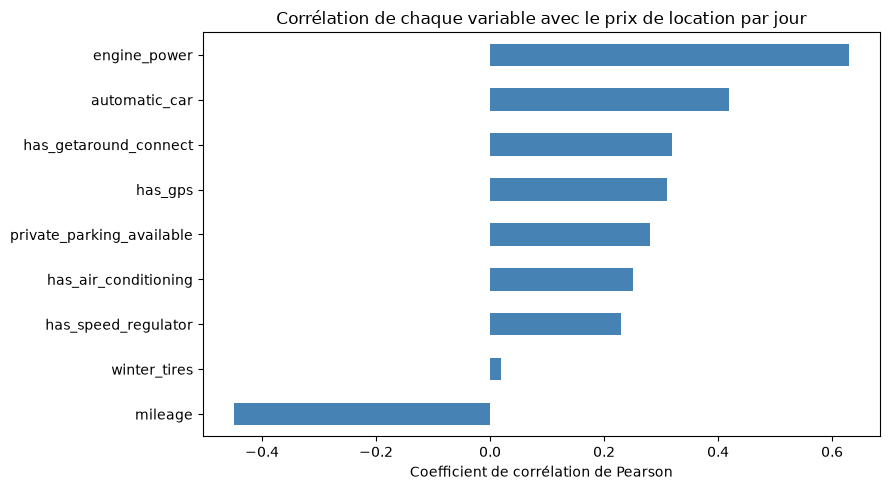

,Pearson,Spearman
mileage,-0.45,-0.40
winter_tires,0.02,-0.01
has_speed_regulator,0.23,0.24
has_air_conditioning,0.25,0.24
private_parking_available,0.28,0.30
has_gps,0.31,0.31
has_getaround_connect,0.32,0.40
automatic_car,0.42,0.43
engine_power,0.63,0.64


In [16]:
# Corrélations avec le prix (booléens convertis en 0/1) : Pearson (linéaire) et Spearman (rangs).
numerique = prix.drop(columns=["model_key", "fuel", "paint_color", "car_type"]).astype(float)
correlations = pd.DataFrame(
    {
        "Pearson": numerique.corr()["rental_price_per_day"],
        "Spearman": numerique.corr(method="spearman")["rental_price_per_day"],
    }
).drop("rental_price_per_day")
correlations = correlations.sort_values("Pearson").round(2)
print(
    f"Corrélation kilométrage / puissance : "
    f"{prix['mileage'].corr(prix['engine_power']):.2f}"
)
ax = correlations["Pearson"].plot.barh(figsize=(9, 5), color="steelblue")
ax.set_title("Corrélation de chaque variable avec le prix de location par jour")
ax.set_xlabel("Coefficient de corrélation de Pearson")
plt.tight_layout()
plt.show()
display(correlations)

> **Interprétation** : le fichier est propre au sens strict (aucune valeur manquante, aucun
> doublon), mais il contient quelques valeurs à traiter.
>
> - **Deux lignes impossibles** : un kilométrage négatif (-64 km, une Renault) et une
>   puissance nulle (une Nissan). Ce sont des erreurs de saisie.
> - **Des extrêmes isolés, que je ne peux pas déclarer faux** : un kilométrage de 1 000 376 km
>   (une Citroën à 37 € par jour ; la suivante est à 484 615 km) ; une puissance maximale de
>   423 ch (une Suzuki à 287 € par jour ; la suivante est à 412 ch), atypique mais cohérente
>   avec son prix élevé ; et 7 voitures louées 10 € par jour, le prix minimal, alors que le
>   premier centile est à 28 €. Ces 7 prix sont très bas pour ces
>   voitures et pourraient être des erreurs de saisie ou des tarifs exceptionnels : rien ne
>   permet de trancher, ni de les juger plausibles.
> - **Des marques rares** : 10 marques sur 28 ont 5 voitures ou moins (Fiat 2, Mini 1, Honda
>   1…). Une marque à une seule voiture ne permet pas d'apprendre un effet de marque fiable.
>   Le parc est aussi presque tout diesel (4 641 voitures sur 4 843), avec 8 hybrides et 3 électriques.
> - **Corrélations** : la puissance est la variable la plus liée au prix (+0,63), puis le
>   kilométrage (-0,45, une voiture plus usée se loue moins cher), la boîte automatique
>   (+0,42), Getaround Connect (+0,32) et le GPS (+0,31). Les pneus hiver n'ont aucune
>   corrélation linéaire avec le prix (+0,02). La puissance et le kilométrage sont peu liés
>   l'un à l'autre (-0,05).

**Comment `train/train.py` traite ces points** : (1) le kilométrage négatif et la puissance
nulle sont remplacés par des valeurs manquantes, puis imputés par la **médiane** à l'intérieur
du pipeline, donc calculée sur l'apprentissage seulement, sans fuite vers le test ; (2) les
extrêmes (1 000 376 km, 423 ch, 10 €) sont **conservés** : rien ne permet de les déclarer
faux, et les forêts et le gradient boosting, qui coupent sur des seuils, y sont peu sensibles
(Ridge, qui standardise, l'est davantage) ; (3) les marques rares ne sont **pas regroupées** :
l'encodage « one-hot » avec `handle_unknown="ignore"` donne un vecteur de zéros à une marque
absente de l'apprentissage, au lieu de faire échouer la prédiction.

*Copyright © 2026 · Auteur : KinSushi · Enzo · Sovralys LLC*